# code_230 · Capstone: constrained storage decisions with learned and planning policies

**Book:** section 43.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_43_GUIDE.md), [execution evidence](../CHAPTER_43_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_230).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Complete projects retain framing, data provenance, baseline comparisons, fitting/selection/calibration boundaries, independent assessment, measured resources and decision authority. Variable resource observations are stored separately from deterministic scientific RESULTS. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency is added. Two capstones reuse existing explicitly pinned checkpoints; the others generate every input internally.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8030;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8030


## State the simulated decision problem and train a policy before final episodes
 An hourly storage system has energy 0–4, initial/target terminal energy 2 and actions−1/0/+1 energy units. Charge/discharge efficiency is0.9. Purchases equal demand plus charging/0.9 or minus 0.9 on discharge; generated demand is always at least 1.1 so no export occurs. Cost is price×purchases plus 0.5 times squared exceedance above grid purchase 3 and a terminal squared energy-target penalty. Capacity and one-unit action power are hard constraints; peak purchase is a soft cost. Generate independent 24-hour price/demand episodes with a known daily mean and unpredictable noise. Q state includes hour, integer energy and three-bin current price/demand. Train 3,000 epsilon-exploring episodes and retain checkpoints at1,000/2,000/3,000; the optimizer sees no final trajectory. Learned policy acts only on current observations and time, never future disturbances.


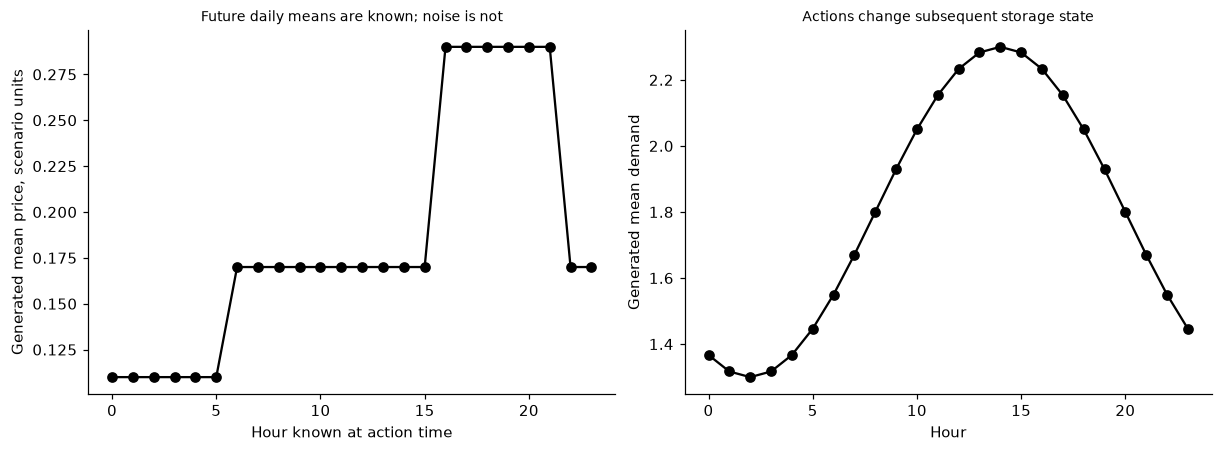

In [2]:
import itertools,hashlib
actions=np.array([-1,0,1]);eta=.9;hours=np.arange(24);mean_price=.17+.12*((hours>=16)&(hours<=21))-.06*((hours<6));mean_demand=1.8+.5*np.sin(2*np.pi*(hours-8)/24);Q=np.zeros((24,5,3,3,3));checkpoints={}
def episode():return np.clip(mean_price+rng.normal(scale=.025,size=24),.05,.5),np.clip(mean_demand+rng.normal(scale=.25,size=24),1.1,3.5)
def state(t,energy,price,demand):return t,int(energy),int(np.digitize(price,[.15,.25])),int(np.digitize(demand,[1.7,2.3]))
def valid_actions(energy):return np.flatnonzero((energy+actions>=0)&(energy+actions<=4))
def step(energy,index,price,demand,last=False):
    action=int(actions[index]);assert index in valid_actions(energy);new=energy+action;purchase=demand+(action/eta if action>0 else action*eta);cost=price*purchase+.5*max(purchase-3,0)**2+(new-2)**2*int(last);assert 0<=new<=4 and abs(action)<=1 and purchase>=0;return new,float(cost),float(purchase)
for ep in range(3000):
    price,demand=episode();energy=2;epsilon=.1+.3*(1-ep/3000)
    for t in range(24):
        s=state(t,energy,price[t],demand[t]);allowed=valid_actions(energy);index=int(rng.choice(allowed)) if rng.random()<epsilon else int(allowed[np.argmax(Q[s][allowed])]);new,cost,purchase=step(energy,index,price[t],demand[t],t==23);target=-cost
        if t<23:
            nxt=state(t+1,new,price[t+1],demand[t+1]);target+=float(np.max(Q[nxt][valid_actions(new)]))
        Q[s+(index,)]+=.1*(target-Q[s+(index,)]);energy=new
    if ep+1 in [1000,2000,3000]:checkpoints[ep+1]=Q.copy()
assert len(checkpoints)==3 and np.all(np.isfinite(Q));RESULTS.update(training_episodes=3000,horizon_hours=24,capacity_energy_units=4,initial_and_target_terminal_energy=2,actions_energy_units=actions.tolist(),efficiency=.9,peak_purchase_is_soft_cost=True,hard_constraints=['energy in [0,4]','absolute action at most1'],reward='negative purchase plus peak and terminal cost',candidate_training_checkpoints=list(checkpoints));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(hours,mean_price,'o-',color='black');axes[0].set(xlabel='Hour known at action time',ylabel='Generated mean price, scenario units',title='Future daily means are known; noise is not');axes[1].plot(hours,mean_demand,'o-',color='black');axes[1].set(xlabel='Hour',ylabel='Generated mean demand',title='Actions change subsequent storage state');plt.show()


## Select on development and compare actual causal policies on shared final disturbances
 A price heuristic charges below 0.14, discharges above 0.25 and otherwise idles, after the same hard action mask. A three-step receding-horizon planner enumerates admissible action sequences using the current observed price/demand and known daily future means, never realized future noise. It includes a horizon-end energy-target penalty as a planning heuristic. Fifty independent development episodes choose the lowest-cost Q checkpoint only. Then compare frozen Q, heuristic and planner on the same 200 new independent episodes, reporting total cost, peak purchase, terminal deviation, physical violations and whole-episode paired uncertainty. Final scores do not choose the checkpoint or planning horizon. No real storage hardware is controlled.


,Frozen Q,Heuristic,Causal planner
cost,8.433735,10.695318,7.973228
peak_purchase,3.404443,2.693148,3.059157
terminal_deviation,0.000000,1.715000,0.000000
violations,0.000000,0.000000,0.000000


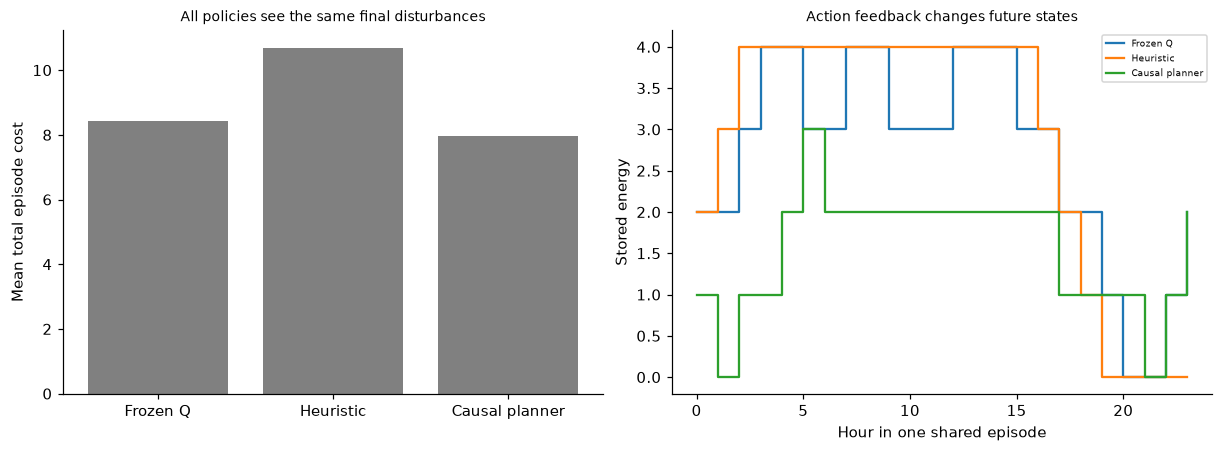

In [3]:
def heuristic(t,energy,price,demand):
    desired=1 if price<.14 else (-1 if price>.25 else 0);index=int(np.flatnonzero(actions==desired)[0]);return index if index in valid_actions(energy) else 1
def learned(table,t,energy,price,demand):
    allowed=valid_actions(energy);return int(allowed[np.argmax(table[state(t,energy,price,demand)][allowed])])
def planner(t,energy,price,demand):
    length=min(3,24-t);best=None
    for sequence in itertools.product(range(3),repeat=length):
        stored=energy;cost=0.;feasible=True
        for offset,index in enumerate(sequence):
            if index not in valid_actions(stored):feasible=False;break
            pp=price if offset==0 else mean_price[t+offset];dd=demand if offset==0 else max(1.1,mean_demand[t+offset]);stored,c,_=step(stored,index,pp,dd,t+offset==23);cost+=c
        if feasible:
            if t+length<24:cost+=.2*(stored-2)**2
            item=(cost,sequence[0]);best=item if best is None or item<best else best
    assert best is not None;return best[1]
def rollout(policy,disturbance):
    price,demand=disturbance;energy=2;cost=0.;trace=[];violations=0
    for t in range(24):
        index=policy(t,energy,price[t],demand[t]);before=energy;energy,c,purchase=step(energy,index,price[t],demand[t],t==23);cost+=c;violations+=int(not(0<=energy<=4 and abs(actions[index])<=1));trace.append({'hour':t,'energy_before':before,'action':int(actions[index]),'energy_after':energy,'price':float(price[t]),'demand':float(demand[t]),'purchase':purchase,'cost':c})
    return {'cost':cost,'peak_purchase':max(r['purchase'] for r in trace),'terminal_deviation':abs(energy-2),'violations':violations,'trace':trace}
development=[episode() for _ in range(50)];dev_cost={steps:float(np.mean([rollout(lambda t,e,p,d,table=table:learned(table,t,e,p,d),dist)['cost'] for dist in development])) for steps,table in checkpoints.items()};chosen=min(dev_cost,key=dev_cost.get);frozen=checkpoints[chosen].copy();policies={'Frozen Q':lambda t,e,p,d:learned(frozen,t,e,p,d),'Heuristic':heuristic,'Causal planner':planner};final_disturbances=[episode() for _ in range(200)];evaluations={name:[rollout(policy,dist) for dist in final_disturbances] for name,policy in policies.items()};profiles={name:{key:float(np.mean([r[key] for r in runs])) for key in ['cost','peak_purchase','terminal_deviation','violations']} for name,runs in evaluations.items()};paired=np.array([r['cost'] for r in evaluations['Frozen Q']])-np.array([r['cost'] for r in evaluations['Heuristic']]);draw=rng.integers(0,200,(2000,200));interval=np.quantile(paired[draw].mean(1),[.025,.975]).tolist();assert all(r['violations']==0 for runs in evaluations.values() for r in runs);RESULTS.update(development_episodes=50,development_checkpoint_cost={str(k):v for k,v in dev_cost.items()},development_selected_training_checkpoint=chosen,independent_shared_final_episodes=200,final_policy_profiles=profiles,paired_Q_minus_heuristic_cost=float(paired.mean()),paired_whole_episode_bootstrap95=interval,final_outcomes_choose_checkpoint=False,planner_future_noise_access=False);display(pd.DataFrame(profiles));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(3),[profiles[name]['cost'] for name in policies],color='.5');axes[0].set(xticks=range(3),xticklabels=list(policies),ylabel='Mean total episode cost',title='All policies see the same final disturbances')
for name,runs in evaluations.items():axes[1].step(hours,[r['energy_after'] for r in runs[0]['trace']],where='post',label=name)
axes[1].set(xlabel='Hour in one shared episode',ylabel='Stored energy',ylim=(-.2,4.2),title='Action feedback changes future states');axes[1].legend(fontsize=6);plt.show()


## Test the fallback and expose the limits of logged-policy evaluation
 If current price leaves the declared[0.05,0.5] support, return a safe idle action and log fallback; an invalid nonfinite observation also idles as a simulated fail-safe rather than emitting a normal model decision. Exhaustively test all five integer energy states with source/unsupported prices and demonstrate that raw unmasked proposals can violate capacity. For logged evaluation, a deterministic heuristic has zero support for some Q actions; no off-policy value is identified there. A separate 200-episode exploratory behaviour chooses the heuristic with probability 0.7 plus a uniform draw over valid actions with probability 0.3, recording exact probabilities. Compute deterministic-target trajectory weights and their effective sample size; product weights may vanish or be highly concentrated even with positive per-step support. Retain that limitation rather than treating the finite importance estimate as a safety certificate. VisualB is an explicit provenance-schema crosswalk for a fictional building; the five capstones remain separate numerical studies.


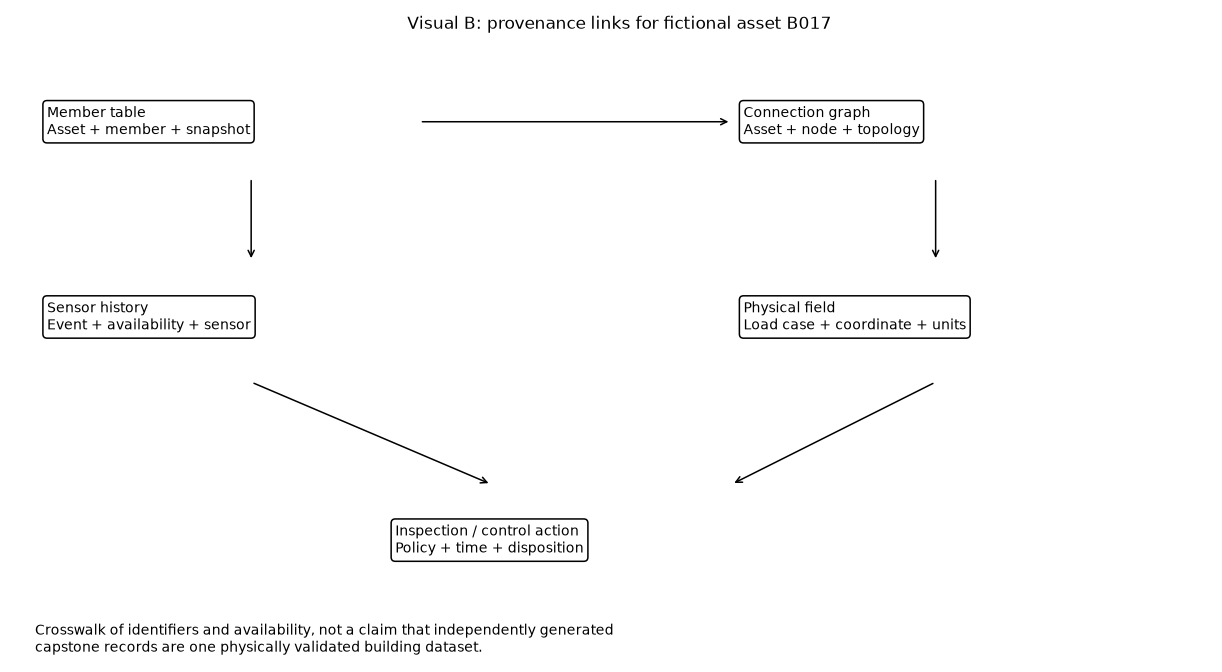

In [4]:
def guarded(t,energy,price,demand):
    if not np.isfinite(price) or not np.isfinite(demand) or not(.05<=price<=.5):return 1,'fallback_idle'
    return learned(frozen,t,energy,price,demand),'learned'
tests=[]
for energy in range(5):
    for price in [.1,.3,.8,float('nan')]:
        index,status=guarded(12,energy,price,2.);assert index in valid_actions(energy);new,c,purchase=step(energy,index,.2,2.);tests.append(status)
raw_violations=sum(not(0<=e+a<=4) for e in range(5) for a in actions);assert raw_violations==2;zero_support=0;weights=[];returns=[]
for _ in range(200):
    price,demand=episode();energy=2;weight=1.;cost=0.
    for t in range(24):
        allowed=valid_actions(energy);hi=heuristic(t,energy,price[t],demand[t]);target=learned(frozen,t,energy,price[t],demand[t]);zero_support+=int(target!=hi);prob=np.zeros(3);prob[allowed]=.3/len(allowed);prob[hi]+=.7;index=int(rng.choice(3,p=prob));weight*=float(index==target)/prob[index];energy,c,_=step(energy,index,price[t],demand[t],t==23);cost+=c
    weights.append(weight);returns.append(cost)
weights=np.array(weights);ess=float(weights.sum()**2/np.sum(weights**2)) if np.any(weights) else 0.;assert zero_support>0 and np.all(weights>=0);provenance={'asset_id':'B017','member_table_key':['asset_id','member_id','snapshot_day'],'connectivity_key':['asset_id','node_id','topology_version'],'sensor_history_key':['asset_id','sensor_id','event_hour','available_hour'],'physical_field_key':['asset_id','load_case','coordinate','unit_contract'],'decision_log_key':['asset_id','hour','policy_version','action','disposition'],'meaning':'schema crosswalk only; numerical capstone datasets are independently generated'};RESULTS.update(fallback_fixture_requests=len(tests),fallback_fixture_dispositions=tests,raw_unmasked_capacity_violations=raw_violations,guarded_capacity_violations=0,deterministic_behaviour_zero_support_Q_state_actions=zero_support,exploratory_logged_episodes=200,trajectory_nonzero_importance_weights=int(np.count_nonzero(weights)),trajectory_importance_ESS=ess,trajectory_IS_cost_observation=float(np.mean(weights*np.array(returns))),finite_IS_observation_is_policy_safety_certificate=False,representation_provenance_crosswalk=provenance);fig,ax=plt.subplots(figsize=(11,6));ax.axis('off');ax.set(xlim=(0,10),ylim=(0,7));labels=[(.3,5.8,'Member table\nAsset + member + snapshot'),(6.1,5.8,'Connection graph\nAsset + node + topology'),(.3,3.7,'Sensor history\nEvent + availability + sensor'),(6.1,3.7,'Physical field\nLoad case + coordinate + units'),(3.2,1.3,'Inspection / control action\nPolicy + time + disposition')]
for x,y,label in labels:ax.text(x,y,label,fontsize=9,va='center',bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
ax.text(3.3,6.8,'Visual B: provenance links for fictional asset B017',fontsize=11)
for a,b in [((3.4,5.8),(6,5.8)),((2,5.2),(2,4.3)),((7.7,5.2),(7.7,4.3)),((2,3),(4,1.9)),((7.7,3),(6,1.9))]:ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->'})
ax.text(.2,.1,'Crosswalk of identifiers and availability, not a claim that independently generated\ncapstone records are one physically validated building dataset.',fontsize=9);plt.show()


In [5]:
summary={'example_id':'code_230','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual finite-horizon storage simulator and tabular Q-learning with independent development checkpoint selection', 'heuristic and causal receding-horizon planner compared on shared independent final episodes', 'hard energy power constraints tested fallback and whole-episode paired uncertainty', 'behaviour support and trajectory importance-weight degeneracy audit plus representation provenance crosswalk'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual finite-horizon storage simulator and tabular Q-learning with independent development checkpoint selection", "heuristic and causal receding-horizon planner compared on shared independent final episodes", "hard energy power constraints tested fallback and whole-episode paired uncertainty", "behaviour support and trajectory importance-weight degeneracy audit plus representation provenance crosswalk"], "elapsed_seconds": 4.026, "example_id": "code_230", "hardware": "Darwin arm64 CPU", "resource_measurements": {}, "results": {"actions_energy_units": [-1, 0, 1], "candidate_training_checkpoints": [1000, 2000, 3000], "capacity_energy_units": 4, "deterministic_behaviour_zero_support_Q_state_actions": 2754, "development_checkpoint_cost": {"1000": 8.74547956663189, "2000": 8.538973016853582, "3000": 8.440028341246155}, "development_episodes": 50, "development_selected_training_checkpoint": 3000, "efficiency": 0.9, "exploratory_logged_episo